# Датасет `fineweb2-rus-v001`

Что получилось после фиксации корпуса и словаря BPE 16 000. Ноутбук читает манифест, колонку длин из `assignments.parquet` и потоки токенов кусками. Текст документов и `train.bin` целиком в память не попадают.

Контекст первой модели в плане — 512 токенов. Файлы пока не нарезаны на такие окна: каждый документ записан целиком, в конце стоит EOS с id 0.

In [1]:
%matplotlib inline

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from tokenizers import Tokenizer

ROOT = Path.cwd().resolve()
if not (ROOT / "environment.yml").exists():
    ROOT = ROOT.parent

DATASET = ROOT / "data" / "fineweb2" / "rus_Cyrl" / "v001" / "dataset"
CONTEXT = 512
VOCAB = 16_000
EOS_ID = 0
SPLIT_ORDER = ("train", "validation", "test")
COLORS = {"train": "#3d6f99", "validation": "#d4762c", "test": "#3e8c6e"}

plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["figure.dpi"] = 120

## Состав выборок

Разбиение 98/1/1, сид 22. В `n_tokens` входит завершающий EOS, поэтому документов ровно столько же, сколько нулей-границ, если ноль больше нигде не встречается.

In [2]:
manifest = json.loads((DATASET / "manifest.json").read_text(encoding="utf-8"))
frame = pq.read_table(
    DATASET / "assignments.parquet",
    columns=["split", "status", "n_tokens"],
).to_pandas()

if not (frame["status"] == "kept").all():
    raise RuntimeError("В назначениях есть отброшенные документы, ноутбук ждёт пустой отсев.")
if frame["n_tokens"].isna().any():
    raise RuntimeError("У сохранённого документа нет длины.")

lengths = {
    name: frame.loc[frame["split"] == name, "n_tokens"].to_numpy(dtype=np.int64)
    for name in SPLIT_ORDER
}
rows = []
for name in SPLIT_ORDER:
    item = manifest["splits"][name]
    got = int(lengths[name].sum())
    if got != item["tokens"] or len(lengths[name]) != item["docs"]:
        raise RuntimeError(f"{name}: таблица не сходится с манифестом.")
    rows.append(
        {
            "выборка": name,
            "документы": item["docs"],
            "токены с EOS": item["tokens"],
            "токены без EOS": item["content_tokens"],
            "символов на токен": round(item["chars_per_content_token"], 2),
            "медиана": int(item["length"]["p50"]),
            "среднее": round(item["length"]["mean"]),
            "доля документов > 512": round(item["length"]["frac_gt_512"], 3),
        }
    )
summary = pd.DataFrame(rows).set_index("выборка")
summary

,документы,токены с EOS,токены без EOS,символов на токен,медиана,среднее,доля документов > 512
выборка,,,,,,,
train,434072,621110567,620676495,3.96,549,1431,0.528
validation,4429,6312766,6308337,3.97,548,1425,0.524
test,4429,5989346,5984917,3.96,562,1352,0.539


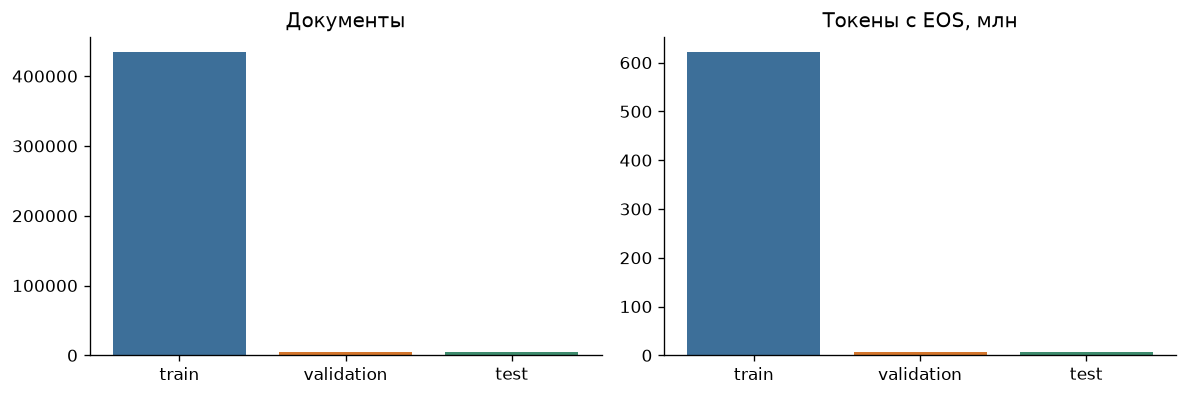

всего токенов с EOS: 633 412 679   без EOS: 632 969 749


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
names = list(SPLIT_ORDER)
x = np.arange(len(names))
docs = [len(lengths[name]) for name in names]
tokens = [int(lengths[name].sum()) / 1e6 for name in names]
colors = [COLORS[name] for name in names]
axes[0].bar(x, docs, color=colors)
axes[0].set_title("Документы")
axes[0].set_xticks(x, names)
axes[1].bar(x, tokens, color=colors)
axes[1].set_title("Токены с EOS, млн")
axes[1].set_xticks(x, names)
fig.tight_layout()
plt.show()

total_tokens = sum(int(lengths[name].sum()) for name in names)
print(
    f"всего токенов с EOS: {total_tokens:,}".replace(",", " "),
    f"  без EOS: {manifest['tokens']['content_tokens']:,}".replace(",", " "),
)

## Длина документов

Среднее заметно выше медианы: хвост длинных страниц тянет его вверх. Validation и test по форме повторяют train, отдельные столбики ниже нужны только чтобы это было видно, а не потому что выборок мало.

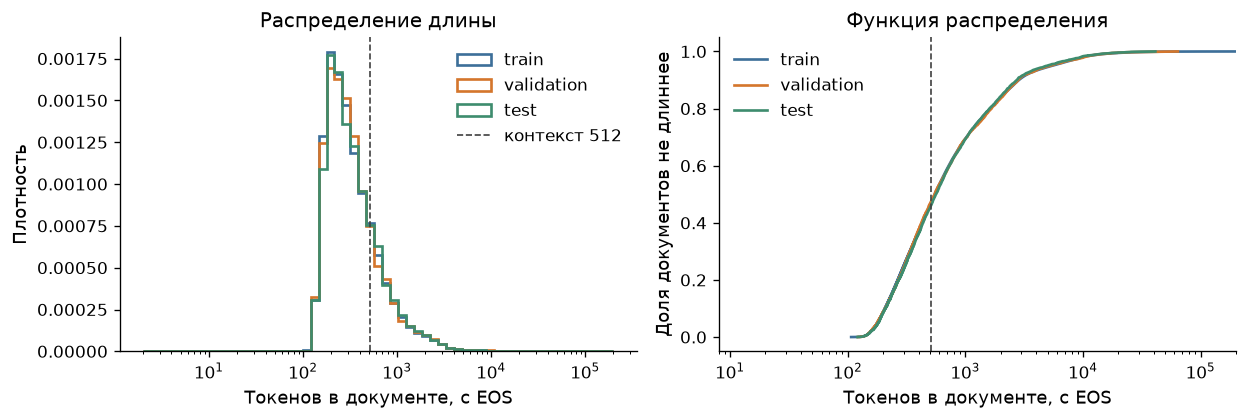

In [4]:
edges = np.logspace(np.log10(2), np.log10(200_000), 60)
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6))
for name in SPLIT_ORDER:
    axes[0].hist(
        lengths[name],
        bins=edges,
        density=True,
        histtype="step",
        linewidth=1.6,
        color=COLORS[name],
        label=name,
    )
axes[0].axvline(CONTEXT, color="0.25", linewidth=1, linestyle="--", label="контекст 512")
axes[0].set_xscale("log")
axes[0].set_xlabel("Токенов в документе, с EOS")
axes[0].set_ylabel("Плотность")
axes[0].set_title("Распределение длины")
axes[0].legend(frameon=False)

for name in SPLIT_ORDER:
    ordered = np.sort(lengths[name])
    cdf = np.arange(1, ordered.size + 1) / ordered.size
    axes[1].plot(ordered, cdf, color=COLORS[name], label=name, linewidth=1.6)
axes[1].axvline(CONTEXT, color="0.25", linewidth=1, linestyle="--")
axes[1].set_xscale("log")
axes[1].set_xlim(8, 200_000)
axes[1].set_xlabel("Токенов в документе, с EOS")
axes[1].set_ylabel("Доля документов не длиннее")
axes[1].set_title("Функция распределения")
axes[1].legend(frameon=False)
fig.tight_layout()
plt.show()

## Что останется внутри окна 512

Если у документа брать только первые N токенов, хвост пропадает. Если позже нарезать его на неперекрывающиеся окна, токены сохраняются, но граница окна не совпадает с границей документа. Ниже — первый вариант: сколько массы лежит в префиксе.

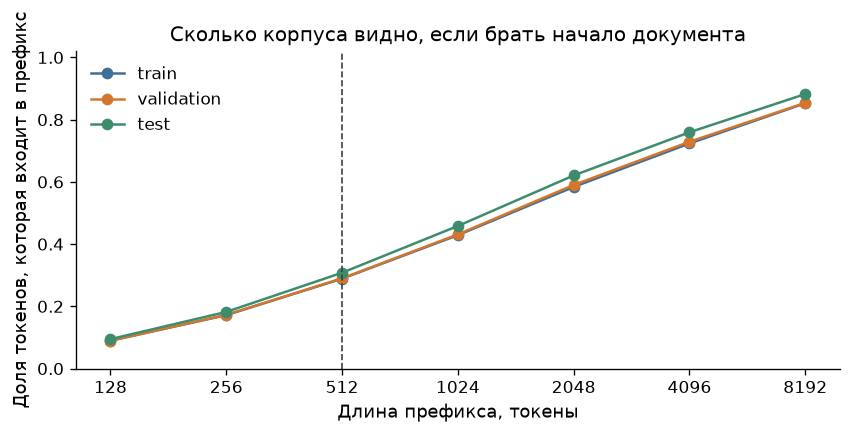

train: документов целиком в окне 512 — 47.2%
train: токенов в первых 512 — 28.9% (179 461 994 из 621 110 567)
train: неперекрывающихся окон по 512, если резать хвост тоже — 1 425 291


In [5]:
caps = np.array([128, 256, 512, 1024, 2048, 4096, 8192])
fig, ax = plt.subplots(figsize=(7.2, 3.6))
for name in SPLIT_ORDER:
    values = lengths[name]
    total = values.sum()
    kept = [np.minimum(values, cap).sum() / total for cap in caps]
    ax.plot(caps, kept, marker="o", color=COLORS[name], label=name)
ax.axvline(CONTEXT, color="0.25", linewidth=1, linestyle="--")
ax.set_xscale("log", base=2)
ax.set_xticks(caps, [str(int(cap)) for cap in caps])
ax.set_ylim(0, 1.02)
ax.set_xlabel("Длина префикса, токены")
ax.set_ylabel("Доля токенов, которая входит в префикс")
ax.set_title("Сколько корпуса видно, если брать начало документа")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

train = lengths["train"]
prefix = int(np.minimum(train, CONTEXT).sum())
whole = int(train.sum())
fit = int(np.count_nonzero(train <= CONTEXT))
windows = int(np.ceil(train / CONTEXT).sum())
def spaced(value: int) -> str:
    return f"{value:,}".replace(",", " ")

print(f"train: документов целиком в окне 512 — {fit / len(train):.1%}")
print(f"train: токенов в первых 512 — {prefix / whole:.1%} ({spaced(prefix)} из {spaced(whole)})")
print(f"train: неперекрывающихся окон по 512, если резать хвост тоже — {spaced(windows)}")

## Какие id встречаются

Счётчик на 16 000 корзин. Файл читается кусками по миллиону токенов, сам массив из 621 млн чисел не создаётся. В таблице куски уже буквами: `·` — пробел перед словом, `↵` — перевод строки.

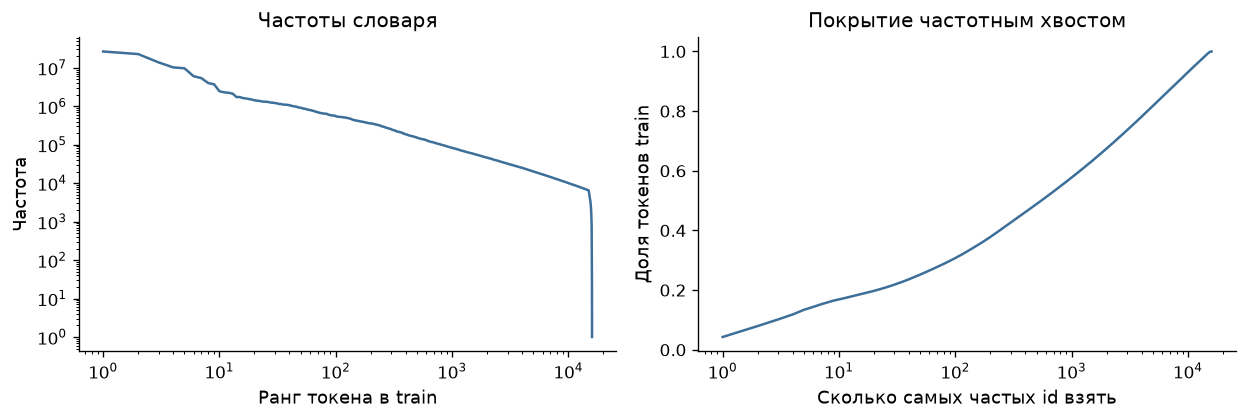

train использует 15951 id из 16000
EOS встречается ровно один раз на документ, доля среди токенов train 0.07%
половину токенов train покрывают 549 самых частых id


,id,токен,доля train
0,12,",",0.042840
1,14,.,0.036668
2,199,↵,0.022261
3,284,·и,0.016534
4,278,·в,0.015641
5,13,-,0.009724
6,312,·на,0.008679
7,280,·с,0.006467
8,329,·не,0.005982
9,26,:,0.003953


In [6]:
def token_counts(path: Path) -> np.ndarray:
    counts = np.zeros(VOCAB, dtype=np.int64)
    mapping = np.memmap(path, dtype="<u2", mode="r")
    try:
        for start in range(0, mapping.size, 1_000_000):
            chunk = np.asarray(mapping[start : start + 1_000_000])
            if int(chunk.max()) >= VOCAB:
                raise RuntimeError(f"В {path.name} есть id вне словаря 16 000.")
            counts += np.bincount(chunk, minlength=VOCAB)
    finally:
        del mapping
    return counts


counts = {name: token_counts(DATASET / "tokens" / f"{name}.bin") for name in SPLIT_ORDER}
train_counts = counts["train"]
n_docs = len(lengths["train"]) + len(lengths["validation"]) + len(lengths["test"])
eos_total = sum(int(counts[name][EOS_ID]) for name in SPLIT_ORDER)
if eos_total != n_docs:
    raise RuntimeError(f"EOS встретился {eos_total} раз при {n_docs} документах.")

used = int(np.count_nonzero(train_counts))
order = np.argsort(train_counts)[::-1]
coverage = np.cumsum(train_counts[order]) / train_counts.sum()
tokenizer = Tokenizer.from_file(str(ROOT / "tokenizers" / "fineweb2_rus_v001" / "chosen" / "tokenizer.json"))

def _byte_decoder() -> dict[str, int]:
    visible = (
        list(range(ord("!"), ord("~") + 1))
        + list(range(ord("¡"), ord("¬") + 1))
        + list(range(ord("®"), ord("ÿ") + 1))
    )
    codepoints = visible[:]
    extra = 0
    for byte in range(256):
        if byte not in visible:
            visible.append(byte)
            codepoints.append(256 + extra)
            extra += 1
    return {chr(point): byte for point, byte in zip(codepoints, visible)}


BYTE_DECODER = _byte_decoder()


def vocab_label(token: str) -> str:
    if token.startswith("<|") and token.endswith("|>"):
        return token
    try:
        raw = bytes(BYTE_DECODER[char] for char in token)
    except KeyError:
        return token
    try:
        text = raw.decode("utf-8")
    except UnicodeDecodeError:
        return "<" + " ".join(f"{byte:02X}" for byte in raw) + ">"
    return text.replace(" ", "·").replace("\n", "↵").replace("\t", "⇥").replace("\r", "␍")


fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6))
ranks = np.arange(1, used + 1)
axes[0].plot(ranks, train_counts[order][:used], color=COLORS["train"])
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_xlabel("Ранг токена в train")
axes[0].set_ylabel("Частота")
axes[0].set_title("Частоты словаря")
axes[1].plot(ranks, coverage[:used], color=COLORS["train"])
axes[1].set_xscale("log")
axes[1].set_xlabel("Сколько самых частых id взять")
axes[1].set_ylabel("Доля токенов train")
axes[1].set_title("Покрытие частотным хвостом")
fig.tight_layout()
plt.show()

top = []
for token_id in order[:15]:
    top.append(
        {
            "id": int(token_id),
            "токен": vocab_label(tokenizer.id_to_token(int(token_id))),
            "доля train": train_counts[token_id] / train_counts.sum(),
        }
    )
print(f"train использует {used} id из {VOCAB}")
print(f"EOS встречается ровно один раз на документ, доля среди токенов train {train_counts[EOS_ID] / train_counts.sum():.2%}")
half = int(np.searchsorted(coverage, 0.5) + 1)
print(f"половину токенов train покрывают {half} самых частых id")
pd.DataFrame(top)

## Отсев и проверка кодирования

Точных копий по SHA-256 текста в NFC нет. MinHash предложил 130 пар между выборками, ни одна не дошла до порога Жаккара 0.8, поэтому `duplicates.jsonl` пустой и выборки не пополнялись. На 2 000 документах декодирование совпало с NFC.

In [7]:
duplicates = (DATASET / "duplicates.jsonl").stat().st_size
near = manifest["dedup"]["near"]
roundtrip = manifest["roundtrip"]
print(f"отброшено документов: {manifest['totals']['discarded_docs']}")
print(f"точных копий: {manifest['totals']['discarded_exact']}")
print(f"пар-кандидатов MinHash: {near['lsh_pairs']}, подтверждено при Жаккаре ≥ {near['jaccard_min']}: {near['confirmed_edges']}")
print(f"duplicates.jsonl: {duplicates} байт")
print(
    f"roundtrip: {roundtrip['docs']} документов, ошибок {roundtrip['failures']}, "
    f"NFC изменил {roundtrip['nfc_changed']}"
)

отброшено документов: 0
точных копий: 0
пар-кандидатов MinHash: 130, подтверждено при Жаккаре ≥ 0.8: 0
duplicates.jsonl: 0 байт
roundtrip: 2000 документов, ошибок 0, NFC изменил 0
